.. index:: Boundary; Dirichlet Conditions

# More General Boundary Conditions
So far we only used natural boundary conditions. Here we discuss how to
set Dirichlet boundary conditions and use different conditions for
different components of the solution.

To fix Dirichlet boundary conditions $u=g$ on part of the boundary
$\Gamma\subset\partial\Omega$ the central class is
`dune.ufl.DirichletBC` which takes three arguments:
the discrete function space for $u$, the function $g$ given by a UFL
expression, and a description of $\Gamma$. There are different ways to
do this. If it is omitted or `None` the condition is applied to the whole
domain, a integer $s>0$ can be provided which can be set to describe a
part of the boundary during grid construction as described in another
place. Finally a UFL condition can be used, i.e., `x[0]<0`.

For vector valued functions $u$ the value function $g$ can be a UFL
vector or a list. In the later case a component of `None` can be used to
describe components which are not to be constrained by the boundary
condition.

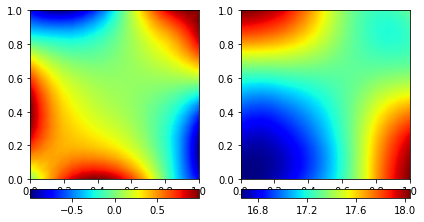

In [1]:
import matplotlib
matplotlib.rc( 'image', cmap='jet' )
from matplotlib import ticker
from dune.fem.plotting import plotComponents

import numpy, io
from dune.grid import structuredGrid as leafGridView
from dune.fem.space import lagrange as solutionSpace
from dune.fem.scheme import galerkin as solutionScheme
from dune.fem.function import gridFunction, cppFunction, integrate, uflFunction
from dune.ufl import DirichletBC, Constant
from ufl import TestFunction, TrialFunction, SpatialCoordinate,\
                dx, ds, grad, inner, sin

gridView = leafGridView([0, 0], [1, 1], [4, 4])
vecSpace = solutionSpace(gridView, dimRange=2, order=2)
x = SpatialCoordinate(vecSpace)
vec = vecSpace.interpolate([0,0], name='u_h')
uVec,vVec = TrialFunction(vecSpace), TestFunction(vecSpace)
a  = ( inner(grad(uVec), grad(vVec)) + inner(uVec,vVec) ) * dx
f  = ( uVec[0]*(1-uVec[1])*vVec[0] + uVec[1]*(1-uVec[0])*vVec[1] ) * dx
# Add nonlinear Neuman boundary conditions for all non Dirichlet boundaries
# for second quantity:
f  = f + uVec[0]*uVec[0] * vVec[1] * ds
# Define dirichlet Boundary conditions for first component on all boundaries
bc = DirichletBC(vecSpace,[sin(4*(x[0]+x[1])),None])
vecScheme = solutionScheme( [a == f, bc],
        parameters={"newton.linear.tolerance": 1e-9} )

vecScheme.solve(target=vec)

plotComponents(vec, gridLines=None, level=2,
               colorbar={"orientation":"horizontal", "ticks":ticker.MaxNLocator(nbins=4)})

To prescribe $u_2=0$ at the bottom boundary is also straightforward - the
Neuman boundary flux added to the right hand side `f` previously will
still be used on the top and vertical boundaries:

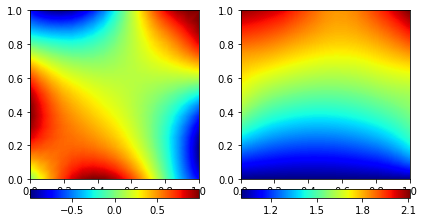

In [2]:
bcBottom = DirichletBC(vecSpace,[sin(4*(x[0]+x[1])),1],x[1]<1e-10)
vecScheme = solutionScheme( [a == f, bc, bcBottom],
        parameters={"newton.linear.tolerance": 1e-9} )
vecScheme.solve(target=vec)
plotComponents(vec, gridLines=None, level=2,
               colorbar={"orientation":"horizontal", "ticks":ticker.MaxNLocator(nbins=4)})

We can also use general grid functions (including discrete functions)
for the boundary conditions in the same way we could use grid functions
anywhere within the UFL forms. So the following code leads to the same
results as above:

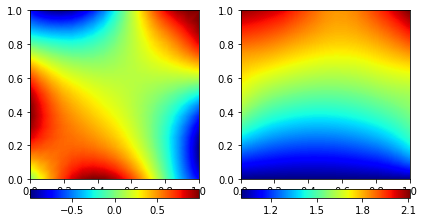

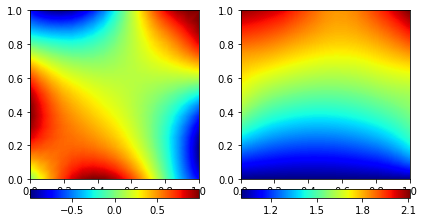

In [3]:
test = vec.copy()
test.clear()
bc = DirichletBC(vecSpace,[vec[0],None])
@gridFunction(gridView ,name="bnd",order=2)
def bnd(x):
    return [numpy.sin(4*(x[0]+x[1])),1]
bcBottom = DirichletBC(vecSpace,bnd,x[1]<1e-10)
vecScheme = solutionScheme( [a == f, bc, bcBottom],
        parameters={"newton.linear.tolerance": 1e-9} )
vecScheme.solve(target=test)
plotComponents(test, gridLines=None, level=2,
               colorbar={"orientation":"horizontal", "ticks":ticker.MaxNLocator(nbins=4)})
assert sum([ abs(td-vd) for td,vd in zip(test.dofVector, vec.dofVector)] ) /\
       len(vec.dofVector) < 1e-7

test.clear()
code="""
#include <cmath>
template <class GridView>
auto bnd() {
  return [](const auto& en,const auto& xLocal) -> auto {
    auto x = en.geometry().global(xLocal);
    return sin(4.*(x[0]+x[1]));
  };
}
"""
bndCpp = cppFunction(gridView, name="bndCpp", order=2,
                     fctName="bnd",includes=io.StringIO(code))
bc = DirichletBC(vecSpace,[bndCpp,None])
vecScheme = solutionScheme( [a == f, bc, bcBottom],
                            parameters={"newton.linear.tolerance": 1e-9} )
vecScheme.solve(target=test)
plotComponents(test, gridLines=None, level=2,
               colorbar={"orientation":"horizontal", "ticks":ticker.MaxNLocator(nbins=4)})
assert sum([ abs(td-vd) for td,vd in zip(test.dofVector, vec.dofVector)] ) /\
       len(vec.dofVector) < 1e-7

We provide a few method, to apply or otherwise access information about
the dirichlet constraints from an existing  scheme.

The following shows how to set all degrees of freedom on the Dirichlet
boundary to zero.

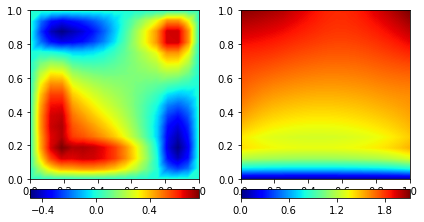

In [4]:
dc = vecScheme.dirichletBlocks
for i,block in enumerate(dc):
    for j,b in enumerate(block):
        if b > 0:
            vec.dofVector[i*len(block)+j] = 0
plotComponents(vec, gridLines=None, level=2,
               colorbar={"orientation":"horizontal", "ticks":ticker.MaxNLocator(nbins=4)})